<a href="https://colab.research.google.com/github/SamueleCesaroni/first/blob/main/Copia_di_exercise_simpleCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial on Convolutional Neural Networks
As we saw during the lesson, CNNs are a class of neural networks able to elaborate structured data such as images. To understand how a CNN works, we aim to build a simple classifier for the recognition of simple images.

**GOAL**:to build a CNN that recognizes if an image contains a rectangle or a circle

## Simple CNN: circle OR rectangle?

### Import generic useful libraries and packages


In [ ]:
import numpy as np
from math import *
from matplotlib import pyplot as plt
#device_name = tf.test.gpu_device_name()
#print(device_name)

### Let's generate some data

We now generate by ourselevs some images with a circle or a rectangle, of random color, in a random position.

Images are matrices/tensors with usually 3 indices that regulates their size: height, lenght and color channels. In the so-called RGB images, the color channels are Red, Green and Blue and their values simply define the colors of the object. In our case, they define the color of the circles and of the rectangles. 2D Medical images are usually gray-scale images, that means that the color channel is one and only one.

Three different modes of generating the images are implemented:

*   A single shape per figure
*   Multiple shapes mixed in each figure (2nd part)
*   A single figure keeping track of the "bounding box" (3rd part)



## First, we write some functions that:
1. Define the background
2. Define the color
3. Draw a circle
4. Draw a rectangle
5. Generates N_samples with the circle/rectangle using the two previous functions with correct targets

In [ ]:
import cv2

def background():
  #here one can add noise
    return np.zeros((64,64,3), np.uint8)

def randomColor():
  return (int(np.random.rand()*128+128),int(np.random.rand()*128+128),int(np.random.rand()*128+128))

def drawCircle(c,x,y,r):
  img = background()
  cv2.circle(img,(x,y),r,c, -1)
  return img,x-r,y-r,x+r,y+r

def genCircle():
  return drawCircle(randomColor(),int(np.random.rand()*50)+10,int(np.random.rand()*50)+10,
                    int(np.random.rand()*6)+3)

def drawRectangle(c,x,y,w,h):
  img = background()
  cv2.rectangle(img,(x,y),((x+w),(y+h)), c, -1)
  return img,x,y,x+w,y+h

def genRectangle():
  return drawRectangle(randomColor(),int(np.random.rand()*40)+10,int(np.random.rand()*40)+10,
                       int(np.random.rand()*12)+5,int(np.random.rand()*12)+5)

nsamples=10000

#produce figures with either a rectangle or a circle
targets=np.random.rand(nsamples) > 0.5
images=np.array([genCircle()[0] if targets[x] else genRectangle()[0] for x in range(nsamples)])

Circles have label 1, Rectangles have label 0.

Let's show a few of the generated images

(10000,)
(10000, 64, 64, 3)
True


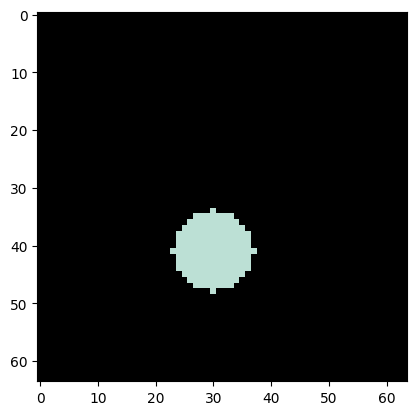

True


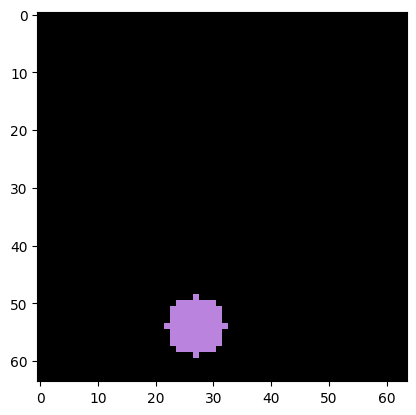

True


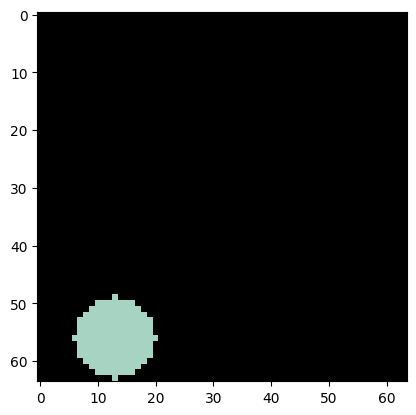

In [ ]:
print(targets.shape)
print(images.shape) # print target shape, images shape and the first 3 labels/targets

print(targets[0])
plt.imshow(images[0])
plt.show()

print(targets[1])
plt.imshow(images[1])
plt.show()

print(targets[2])
plt.imshow(images[2])
plt.show()

# plot the first three images and look if the targets correspond to the images


### Additional Exercise
You can try this exercise once you have finished the main notebook.
1. Try adding some random noise in the image background
2. Try adding more classes such e.g. Lines or Ellipses

### Let's build a CNN
During the class, we have seen the typical structure of a CNN:

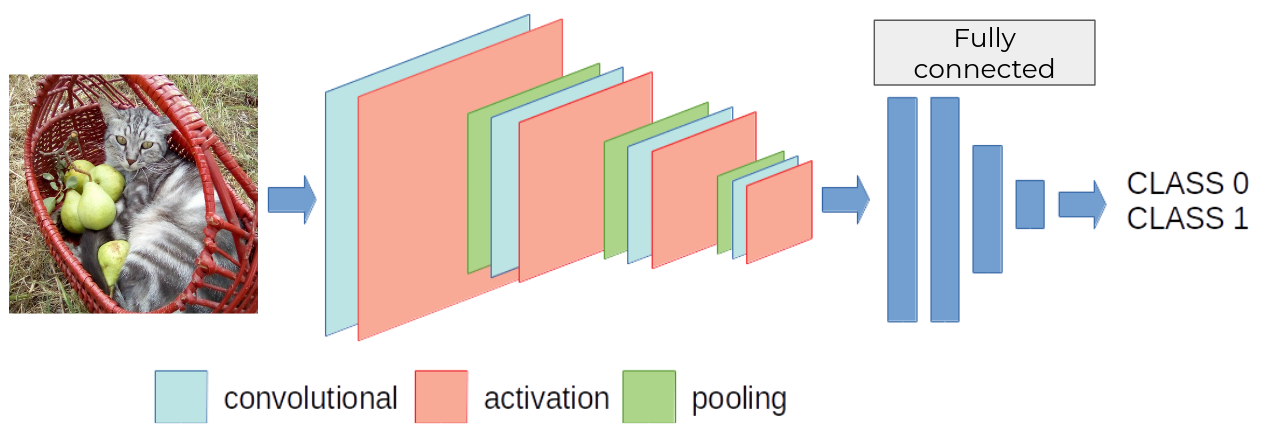


Now we build our first CNN. We need to proceed through the following steps:

1. Import the correct layers from keras;
2. Import and define the Model we want to develop;
3. Compile the model;
4. Print a summary of the model and show its draw.

Please ALWAYS refer to the documentation if you have some doubt:  https://keras.io/api/

### MaxPooling
![alt text](https://computersciencewiki.org/images/8/8a/MaxpoolSample2.png)

### Exercise
5. Try adding/removing convolutional layers, change the kernel size, try to add dropout
### Additional Exercise
6. Try changing the model to categorical labels, change loss function from binary_crossentropy to categorical_crossentropy, and use softmax activation instead of sigmoid

In [ ]:
from keras.layers import Input, Conv2D, Flatten, MaxPool2D, Dense
from keras.models import Model
from keras.utils import plot_model
import tensorflow as tf
import keras
keras.backend.clear_session()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 60, 60, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 20, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 18, 18, 3)      │           138 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 3)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 108)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,090 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,619 (6.32 KB)

 Trainable params: 1,619 (6.32 KB)

 Non-trainable params: 0 (0.00 B)

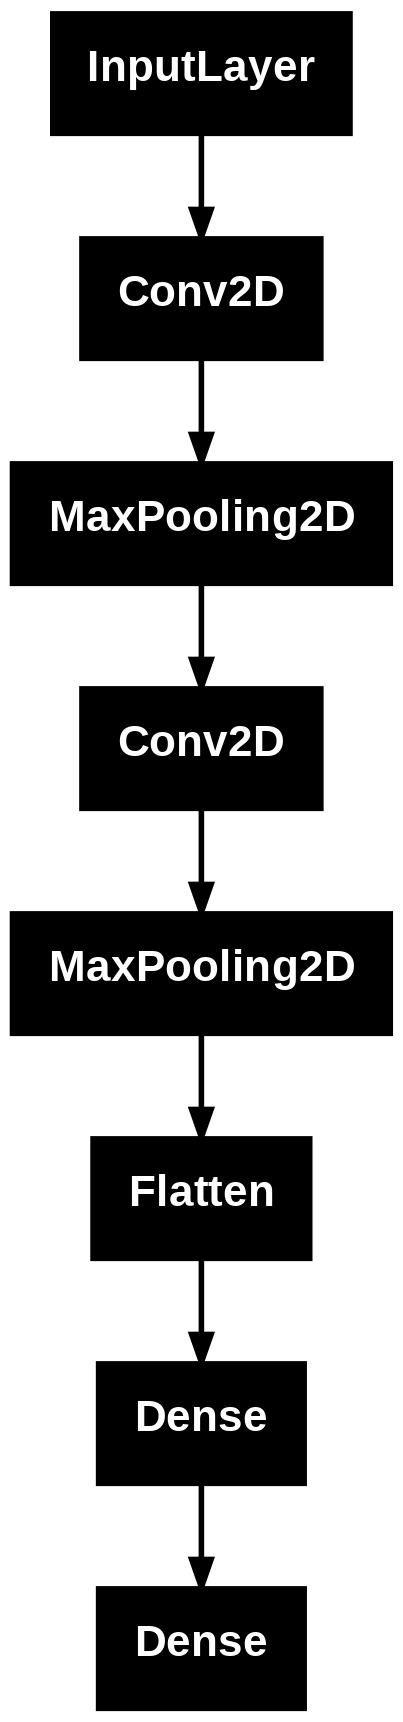

In [ ]:
def SimpleModel(): #write this simple model, the output below may help you in understanding which layers you could use
  inputs=Input (shape= (64,64,3,))
  hidden= Conv2D(5,5, activation=' relu')(inputs)
  hidden= MaxPool2D( (2,2) )(hidden)
  hidden= Conv2D(5,3, activation='relu')(hidden)
  hidden= MaxPool2D( (2,2) )(hidden)
  hidden=Flatten()(hidden)
  hidden=Dense(5, activation=' relu') (hidden)
  outputs = Dense(1, activation='sigmoid' )(hidden)
  simple_model = Model(inputs=inputs, outputs=outputs)
  simple_model.compile(loss='binary_crossentropy', optimizer='adam' ,metrics=['accuracy'])
  return simple model

SimModel = SimpleModel()
SimModel.summary()
plot_model(SimModel, to_file='model.png')


### Let's train the CNN
This means to fit it to our data.

The sample is automatically split in two so that 50% of it is used for validation and the other half for training


In [ ]:
history=SimModel.fit(..., epochs=50, validation_split=?)

Epoch 1/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.6277 - loss: 1.0893 - val_accuracy: 0.8810 - val_loss: 0.2891
Epoch 2/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9445 - loss: 0.1907 - val_accuracy: 0.9962 - val_loss: 0.0440
Epoch 3/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9957 - loss: 0.0306 - val_accuracy: 0.9998 - val_loss: 0.0098
Epoch 4/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9994 - loss: 0.0080 - val_accuracy: 0.9998 - val_loss: 0.0051
Epoch 5/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 1.0000 - val_loss: 0.0031
Epoch 6/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 1.0000 - val_loss: 0.0022
Epoch 7/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 8/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 0.0017 - val_accuracy: 1

*history* contains information about the training.  We can now now show the loss vs epoch for both validation and training samples.




dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


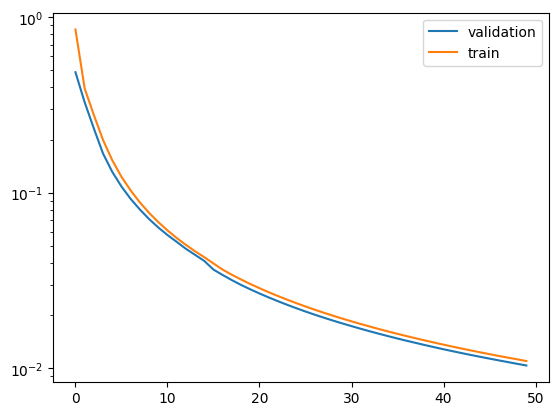

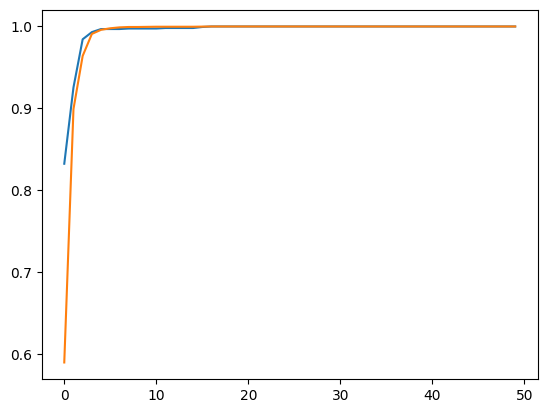

In [ ]:
print(history.history.keys())
plt.plot(history.history["val_loss"], label = 'validation')
plt.plot(history.history["loss"], label = 'train')
plt.legend()
plt.yscale('log')
plt.show()
plt.plot(history.history["val_accuracy"],  label = 'validation')
plt.plot(history.history["accuracy"],  label = 'train')
plt.show()


### Is our model properly working?
Now we generate one more circle and one more rectangle and we use the CNN to predict their class.

In [ ]:
test_rectangle = SimModel.predict(np.expand_dims(genRectangle()[0],axis=0) )
test_circle = SimModel.predict(np.expand_dims(genCircle()[0],axis=0) )

print('The predicted label for test_rectangle is', np.round((test_rectangle)))
print('The predicted label for test_circle is', np.round((test_circle)))


#print(model.predict(np.expand_dims(genCircle()[0]+genCircle()[0]+genCircle()[0]+genCircle()[0],axis=0) ))
#print(model.predict(np.expand_dims(genCircle()[0]+genCircle()[0]+genCircle()[0]+genCircle()[0],axis=0) ))
#print(model.predict((genCircle()[0]+genCircle()[0]+genCircle()[0]).reshape(1,64,64,3)))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
The predicted label for test_rectangle is [[0.]]
The predicted label for test_circle is [[1.]]


## A correct data managing
In the exercise above, we generated our data, we split them into training and validation and finally we generated one circle and one rectangle to check if our CNN was correctly classifying them.
Now, in "real life", this is not completely correct. A function that you will need is taken from the scikit-learn library and it is called train_test_split (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(images, targets, train_size=0.8, random_state=42)

In [ ]:
SimModelCorr = SimpleModel()

In [ ]:
history= SimModelCorr.fit(x_train, y_train, epochs=50, validation_split=0.2)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4840 - loss: 1.8336 - val_accuracy: 0.8325 - val_loss: 0.4868
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8807 - loss: 0.4313 - val_accuracy: 0.9256 - val_loss: 0.3283
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9462 - loss: 0.3056 - val_accuracy: 0.9844 - val_loss: 0.2326
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9869 - loss: 0.2159 - val_accuracy: 0.9931 - val_loss: 0.1673
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9964 - loss: 0.1612 - val_accuracy: 0.9969 - val_loss: 0.1317
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9975 - loss: 0.1308 - val_accuracy: 0.9969 - val_loss: 0.1086
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9986 - loss: 0.1085 - val_accuracy: 0.9969 - val_loss: 0.0923
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9997 - loss: 0.0908 - val_accuracy: 0.

In [ ]:
prediction_on_test = SimModelCorr.predict(x_test)
classification_performance = classification_report(y_test, np.round(prediction_on_test))
print(classification_performance)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
              precision    recall  f1-score   support

       False       1.00      1.00      1.00      1001
        True       1.00      1.00      1.00       999

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



### Let's generate some data

## CNN for regression: how many rectangles and circles are on the image?
We have seen the simplest case of a binary classification before. Now, we want to generate images where there are both rectangles and circles and to train a neural network that is ables to give as answer the number of circles and rectangles in the image.

First of all, we need to generate the images, using the fuctions that we previously defined.

In [ ]:
def genN(f,i):
  img = np.zeros((64,64,3), np.uint8)
  for x in range(i):
    img+=f()[0] #discard bb info, take only image
  return img

targets=np.array([(int(np.random.rand()*4),int(np.random.rand()*4)) for x in range(nsamples) ])
images=np.array([genN(genRectangle,targets[x,0])+genN(genCircle,targets[x,1]) for x in range(nsamples)])

(10000, 2)
(10000, 64, 64, 3)
[1 2]


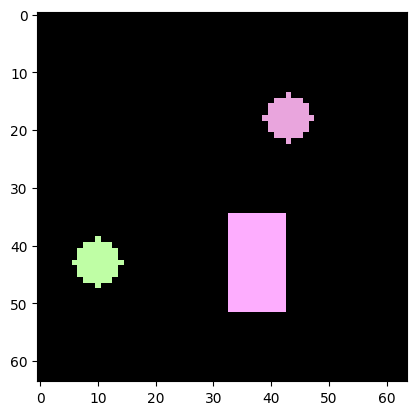

[3 3]


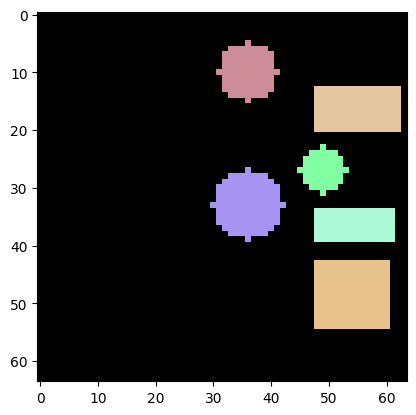

[0 1]


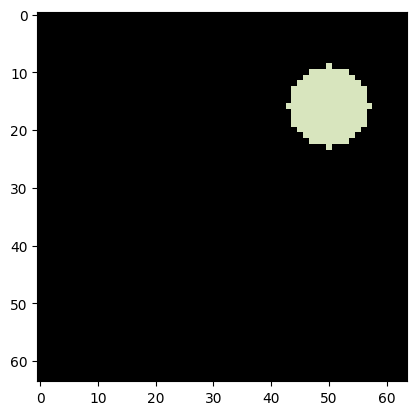

In [ ]:
# print target shape, images shape and the first 3 labels/targets

# plot the first three images and look if the targets correspond to the images
print(targets.shape)
print(images.shape) # print target shape, images shape and the first 3 labels/targets

print(targets[0])
plt.imshow(images[0])
plt.show()

print(targets[1])
plt.imshow(images[1])
plt.show()

print(targets[2])
plt.imshow(images[2])
plt.show()

### Let's build the CNN

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 60, 60, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 20, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 18, 18, 3)      │           138 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 3)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 108)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,090 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,621 (6.34 KB)

 Trainable params: 1,619 (6.32 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

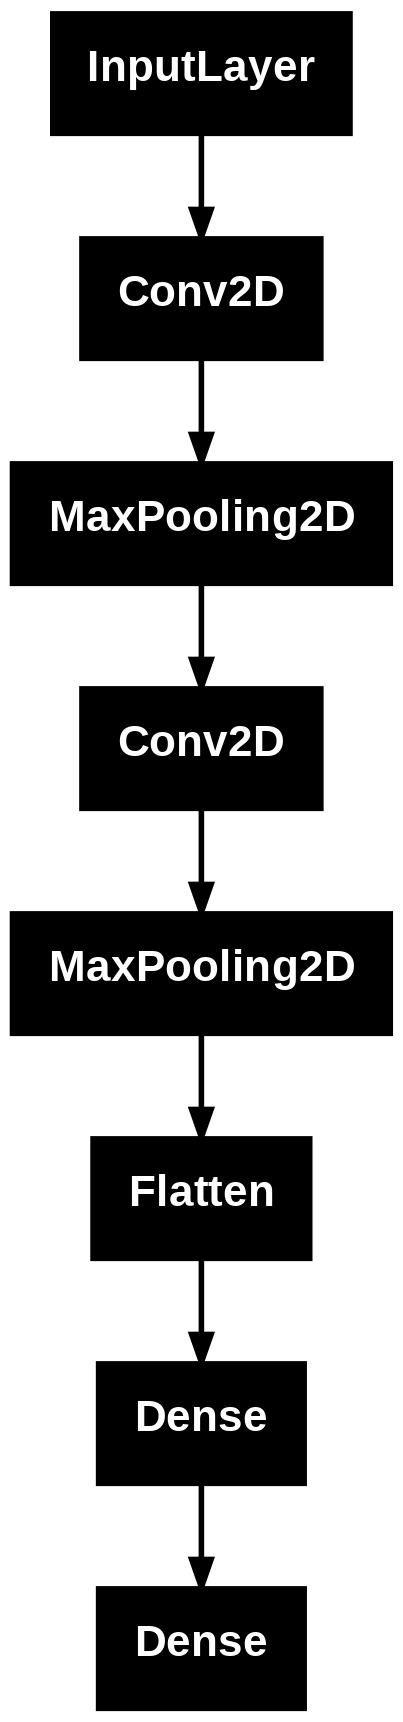

In [ ]:
def CounterModel():
  inputs=Input(shape=(64,64,3,))
 # ...
  outputs = Dense(2, activation='linear')(hidden)
#
  simple_model = Model(inputs=inputs, outputs=outputs)
  simple_model.compile(loss=, optimizer=,metrics=[])
  return simple_model

CountModel = CounterModel()
SimModel.summary()
plot_model(SimModel, to_file='model.png')


Let's try to mix an image with circles and rectangles and see how the network would evaluate it

### Let's train the CNN!

In [ ]:
#x_train, x_test, y_train, y_test = train_test_split() #fill in

In [ ]:
history_count = CountModel.fit(, , epochs=100, validation_split= 0.2)#fill in

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - MAE: 10.3287 - loss: 275.4108 - val_MAE: 2.7380 - val_loss: 13.1331
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - MAE: 2.3435 - loss: 9.4936 - val_MAE: 1.7121 - val_loss: 5.0528
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - MAE: 1.5969 - loss: 4.2891 - val_MAE: 1.3696 - val_loss: 3.1655
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - MAE: 1.3103 - loss: 2.8012 - val_MAE: 1.1980 - val_loss: 2.3661
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - MAE: 1.1845 - loss: 2.2043 - val_MAE: 1.0913 - val_loss: 1.9019
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - MAE: 1.0761 - loss: 1.7923 - val_MAE: 1.0255 - val_loss: 1.6274
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - MAE: 1.0244 - loss: 1.5841 - val_MAE: 0.9844 - val_loss: 1.4622
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - MAE: 0.9746 - loss: 1.4123 - val_MAE: 0.9573 - val_loss: 1.3541
Epoch 9/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 

dict_keys(['MAE', 'loss', 'val_MAE', 'val_loss'])


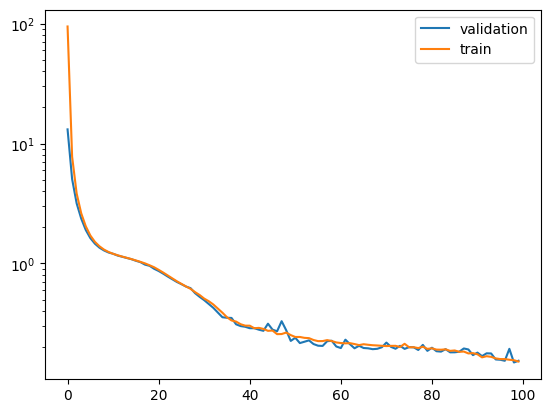

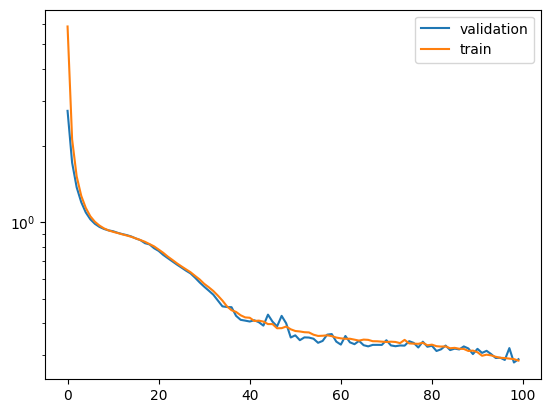

In [ ]:
print(history_count.history.keys())  #fill in
plt.plot(history_count.history["val_loss"], label= 'validation')
plt.plot(history_count.history["loss"], label= 'train')
plt.yscale('log')
plt.legend()
plt.show()

plt.plot(history_count.history["val_MAE"], label= 'validation')
plt.plot(history_count.history["MAE"], label= 'train')
plt.yscale('log')
plt.legend()
plt.show()

In [ ]:
prediction_counter = CountModel.predict(x_test) #fill in

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step


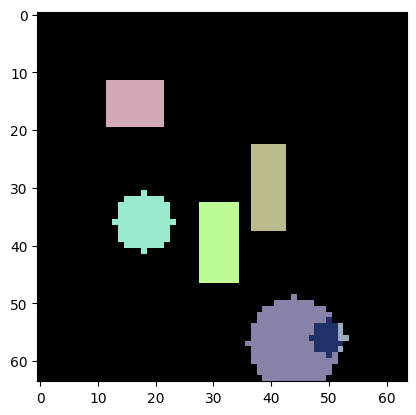

The label for this case is: [3 3]
According to the prediction, there are 3.088085412979126 rectangles and 2.4427576065063477 circles


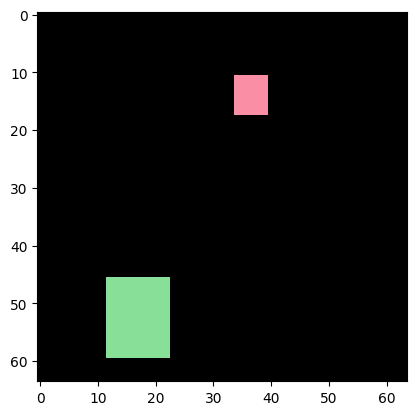

The label for this case is: [2 0]
According to the prediction, there are 1.761326551437378 rectangles and 0.12990932166576385 circles


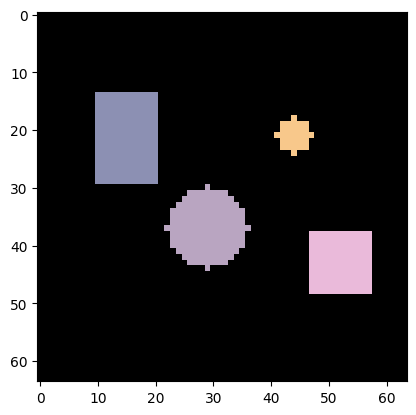

The label for this case is: [2 2]
According to the prediction, there are 2.247563123703003 rectangles and 2.200941324234009 circles


In [ ]:
plt.imshow(x_test[0])
plt.show()
print('The label for this case is:', y_test[0])
print(f"According to the prediction, there are {prediction_counter[0][0]} rectangles and {prediction_counter[0][1]} circles")

plt.imshow(x_test[12])
plt.show()
print('The label for this case is:', y_test[12])
print(f"According to the prediction, there are {prediction_counter[12][0]} rectangles and {prediction_counter[12][1]} circles")

plt.imshow(x_test[25])
plt.show()
print('The label for this case is:', y_test[25])
print(f"According to the prediction, there are {prediction_counter[25][0]} rectangles and {prediction_counter[25][1]} circles")

## CNN and bounding box
Even if here the problem is "trivial", it is intersting to see how this networks work with a bounding box where the model has to classify the shape AND to provide the bounding box coordinates (detection problem).
1. Let's create the data;
2. We will concatenate the classification (targets) and the detection (boundingBoxes)
3. We will change the previous networks according to the new problem.

## Let's generate some data!

In [ ]:
nsamples=10000
targets=np.array([np.random.rand()>0.5 for x in range(nsamples) ])
imagesWithBB=[genCircle() if targets[x] else genRectangle() for x in range(nsamples)]
images=np.array([imagesWithBB[x][0] for x in range(nsamples)])
boundingBoxes=np.array([imagesWithBB[x][1:] for x in range(nsamples)])

labels=[targets,boundingBoxes]
data=images
#    return data,labels, boundingBoxes
#data, labels, boundingBoxes = genwithBB()

Let's visualize the results of the data generation!

False


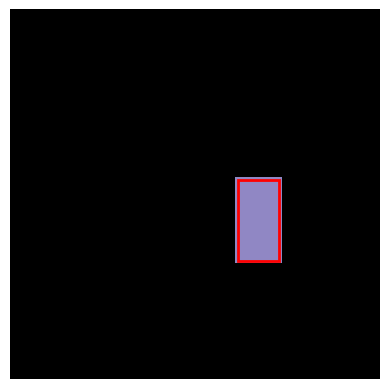

In [ ]:
import matplotlib.patches as patches
print(labels[0][2])
ig, ax = plt.subplots(1)
ax.imshow(images[2])

# Create a rectangle patch
bbox = patches.Rectangle((boundingBoxes[2][0], boundingBoxes[2][1]), boundingBoxes[2][2] - boundingBoxes[2][0], boundingBoxes[2][3] - boundingBoxes[2][1],
                         linewidth=2, edgecolor='red', facecolor='none')

# Add the patch to the Axes
ax.add_patch(bbox)

# Save the result
plt.axis('off')
plt.show()


## Let's build the CNN

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 60, 60, 5) │        380 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 20, 20, 5) │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 18, 18, 3) │        138 │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 6, 6, 3)   │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 108)       │          0 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 20)        │      2,180 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classification      │ (None, 1)         │         21 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ regression (Dense)  │ (None, 4)         │         84 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,803 (10.95 KB)

 Trainable params: 2,803 (10.95 KB)

 Non-trainable params: 0 (0.00 B)

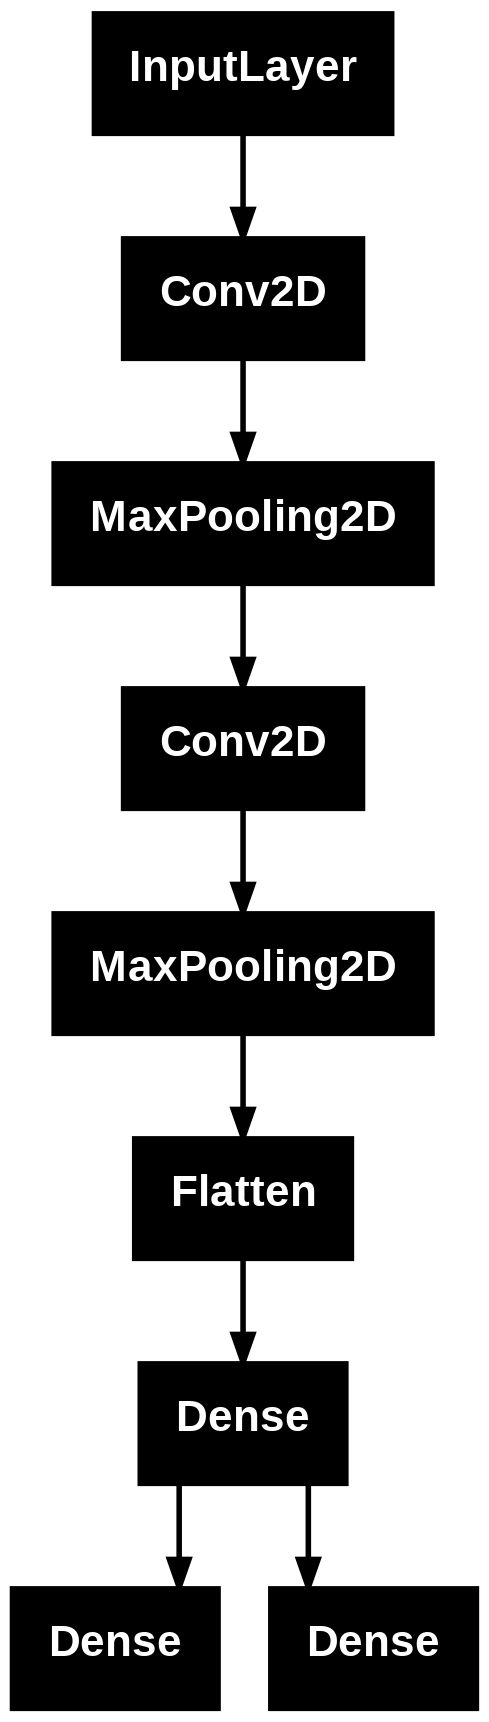

In [ ]:
import keras
keras.backend.clear_session()

def BBModel(): #fill in
  inputs=Input(shape=(64,64,3,))
  #...
  hidden=  Dense(20, activation='relu')(hidden)
  #output1 = Dense(..., name='classification')(hidden)
  #output2 = Dense(..., name = 'regression')(hidden)
  #outputs=[output1,output2]
  #...
  loss={'classification': "?",
        'regression': "?"}
  metrics={'classification': "?",
        'regression': "?"}
  bb_model = Model(inputs=inputs, outputs=outputs)
  bb_model.compile(loss=loss, optimizer='adam',metrics=metrics)
  return bb_model

BoundingBoxModel = BBModel()
BoundingBoxModel.summary()
plot_model(BoundingBoxModel, to_file='model.png')


## Let's fit the CNN

In [ ]:
history_bb = BoundingBoxModel.fit(data, labels, validation_split= 0.8, epochs=150)

Print the loss and metric curves.

In [ ]:
print(history_bb.history.keys())

dict_keys(['classification_accuracy', 'classification_loss', 'loss', 'regression_MAE', 'regression_loss', 'val_classification_accuracy', 'val_classification_loss', 'val_loss', 'val_regression_MAE', 'val_regression_loss'])


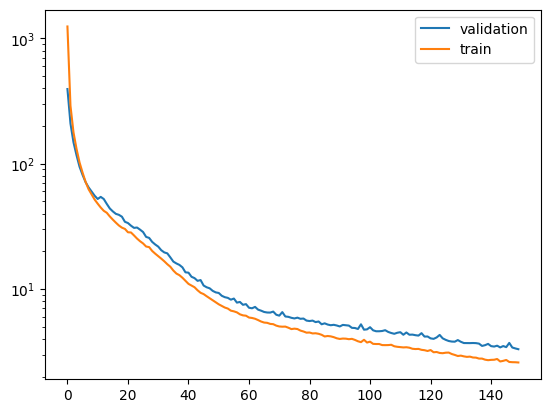

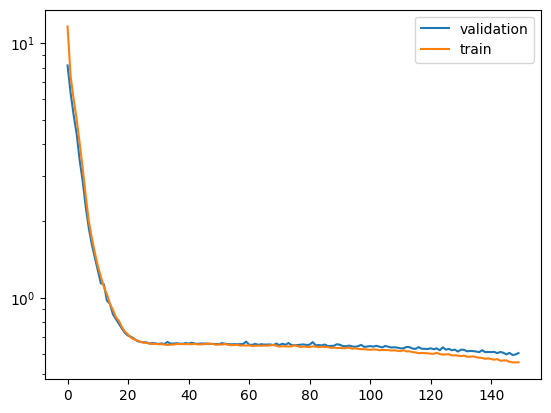

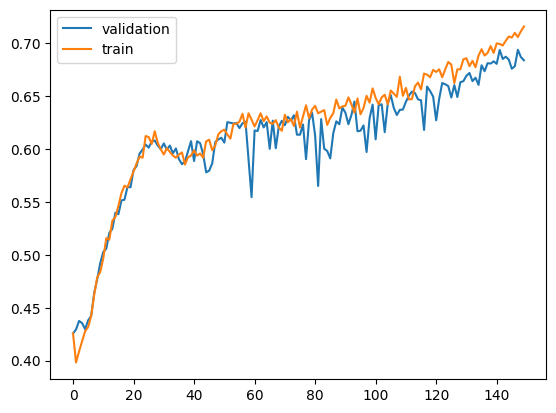

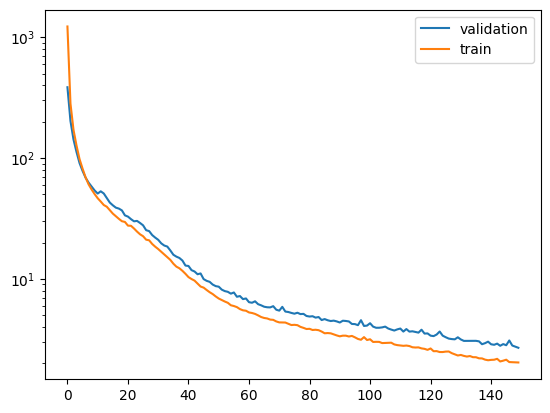

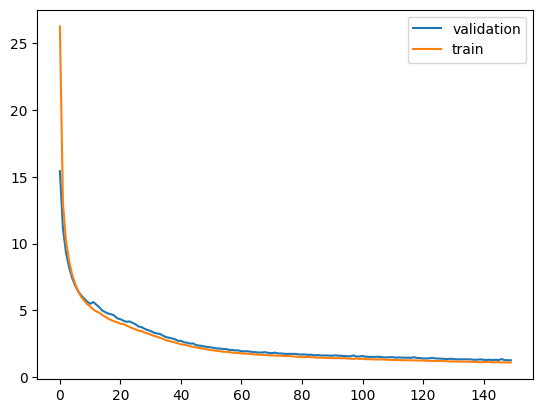

In [ ]:
plt.plot(history_bb.history["val_loss"], label= 'validation')
plt.plot(history_bb.history["loss"], label= 'train')
plt.yscale('log')
plt.legend()
plt.show()

plt.plot(history_bb.history["val_classification_loss"], label= 'validation')
plt.plot(history_bb.history["classification_loss"], label= 'train')
plt.yscale('log')
plt.legend()
plt.show()

plt.plot(history_bb.history["val_classification_accuracy"], label= 'validation')
plt.plot(history_bb.history["classification_accuracy"], label= 'train')
plt.legend()
plt.show()

plt.plot(history_bb.history["val_regression_loss"], label= 'validation')
plt.plot(history_bb.history["regression_loss"], label= 'train')
plt.yscale('log')
plt.legend()
plt.show()

plt.plot(history_bb.history["val_regression_MAE"], label= 'validation')
plt.plot(history_bb.history["regression_MAE"], label= 'train')
plt.legend()
plt.show()

Here, instead of using train test split, we sample a new set using the function that originated our data. You can choose the number of samples you like.

In [ ]:
n_testsamples=32
targets=np.array([np.random.rand()>0.5 for x in range(n_testsamples) ])
imagesWithBB=[genCircle() if targets[x] else genRectangle() for x in range(n_testsamples)]
images=np.array([imagesWithBB[x][0] for x in range(n_testsamples)])
boundingBoxes=np.array([imagesWithBB[x][1:] for x in range(n_testsamples)])

labels_test=[targets,boundingBoxes]
data_test=images

In [ ]:
prediction_bb = BoundingBoxModel.predict(data_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step


In [ ]:
classification_performance = classification_report(labels_test[0], np.round(prediction_bb[0])) #fill in
print(classification_performance)

              precision    recall  f1-score   support

       False       0.69      0.69      0.69        16
        True       0.69      0.69      0.69        16

    accuracy                           0.69        32
   macro avg       0.69      0.69      0.69        32
weighted avg       0.69      0.69      0.69        32



False


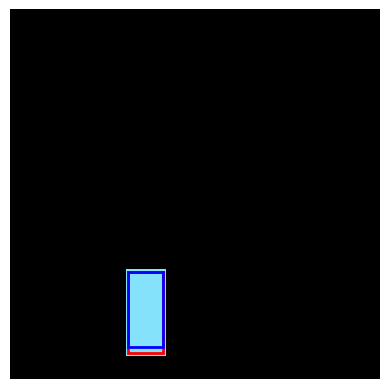

In [ ]:
num = 13
print(labels_test[0][num])
ig, ax = plt.subplots(1)
ax.imshow(data_test[num])

# Create a rectangle patch
bbox = patches.Rectangle((labels_test[1][num][0], labels_test[1][num][1]), labels_test[1][num][2] - labels_test[1][num][0], labels_test[1][num][3] - labels_test[1][num][1], linewidth=2, edgecolor='red', facecolor='none')
bbox_pred = patches.Rectangle((int(prediction_bb[1][num][0]), int(prediction_bb[1][num][1])), int(prediction_bb[1][num][2]) - int(prediction_bb[1][num][0]), int(prediction_bb[1][num][3]) - int(prediction_bb[1][num][1]), linewidth=2, edgecolor='blue', facecolor='none')
# Add the patch to the Axes
ax.add_patch(bbox)
ax.add_patch(bbox_pred)
# Save the result
plt.axis('off')
plt.show()


# Bonus

The following code can be used to visualize what features the first conv layer is looking at

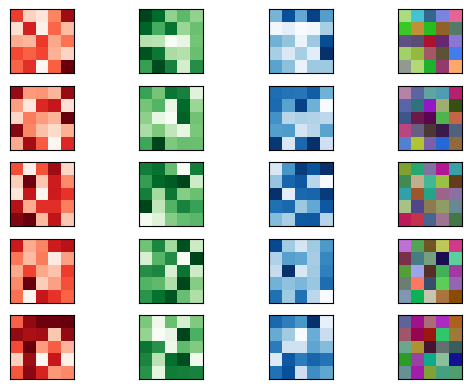

In [ ]:
# retrieve weights from the second hidden layer
filters, biases = SimModel.layers[1].get_weights()
# normalize filter values to 0-1 so we can visualize them
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)
# plot first few filters
n_filters, ix =5, 1
for i in range(n_filters):
	# get the filter
	f = filters[:, :, :, i]
	# plot each channel separately
	for j in range(3):
		# specify subplot and turn of axis
		ax = plt.subplot(n_filters, 4, ix)
		ax.set_xticks([])
		ax.set_yticks([])
		# plot filter channel in grayscale
		plt.imshow(f[:, :, j], cmap=['Reds','Greens','Blues'][j])
		ix += 1
	ax = plt.subplot(n_filters, 4, ix)
	ax.set_xticks([])
	ax.set_yticks([])
	plt.imshow(f)
	ix += 1


# show the figure
plt.show()